In [1]:
# Install necessary dependencies for Spark and Hugging Face Dataset downloads
!pip install -q pyspark huggingface_hub

import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession
from pyspark.sql.functions import *
from pyspark.sql.types import *
from huggingface_hub import hf_hub_download

# Initialize a local Spark Session
spark = SparkSession.builder \
    .appName("Agricultural Data Analysis")\
    .master("local[*]")\
    .getOrCreate()

print("Spark Version:", spark.version)
print("Spark Session Created Successfully")
print("Application Name:", spark.sparkContext.appName)
print("Master:", spark.sparkContext.master)
print("Default Parallelism:", spark.sparkContext.defaultParallelism)

Spark Version: 4.0.5
Spark Session Created Successfully
Application Name: Agricultural Data Analysis
Master: local[*]
Default Parallelism: 2


### 2. Dataset Loading and Initial Exploration

In [2]:
# Download the dataset from Hugging Face Repository
file_path = hf_hub_download(
    repo_id="jason1966/abhinand05_crop-production-in-india",
    filename="crop_production.csv",
    repo_type="dataset"
)
print("Dataset downloaded to:", file_path)

# Load the CSV file into a Spark DataFrame
df = spark.read \
    .option("header", "true") \
    .option("inferSchema", "true") \
    .csv(file_path)

# Basic dataset size and schema check
df.show(10)
df.printSchema()
print("Total Rows:", df.count())
print("Total Columns:", len(df.columns))
df.describe().show()

crop_production.csv: reconstructing file:   0%|          |  0.00B / 15.3MB            

crop_production.csv: downloading bytes:           |  0.00B            

Dataset downloaded to: /root/.cache/huggingface/hub/datasets--jason1966--abhinand05_crop-production-in-india/snapshots/5ae2ef111a28e9c67bb60d72159343003d8f49cd/crop_production.csv
+--------------------+-------------+---------+-----------+-------------------+-------+----------+
|          State_Name|District_Name|Crop_Year|     Season|               Crop|   Area|Production|
+--------------------+-------------+---------+-----------+-------------------+-------+----------+
|Andaman and Nicob...|     NICOBARS|     2000|Kharif     |           Arecanut| 1254.0|    2000.0|
|Andaman and Nicob...|     NICOBARS|     2000|Kharif     |Other Kharif pulses|    2.0|       1.0|
|Andaman and Nicob...|     NICOBARS|     2000|Kharif     |               Rice|  102.0|     321.0|
|Andaman and Nicob...|     NICOBARS|     2000|Whole Year |             Banana|  176.0|     641.0|
|Andaman and Nicob...|     NICOBARS|     2000|Whole Year |          Cashewnut|  720.0|     165.0|
|Andaman and Nicob...|     NICOBARS|

### 3. Data Profiling, Duplicate Detection, and Null Checks

In [ ]:
# 1. Checking missing values per column
df.select([
    count(when(col(c).isNull(), c)).alias(c)
    for c in df.columns
]).show()

# 2. Check unique value counts
for c in df.columns:
    print(c, ":", df.select(c).distinct().count())

# 3. Class distribution checks
print("Top 15 Crops Distribution:")
df.groupBy("Crop").count().orderBy("count", ascending=False).show(15, truncate=False)

print("Season Distribution:")
df.groupBy("Season").count().orderBy("count", ascending=False).show()

print("Year-wise distribution:")
df.groupBy("Crop_Year").count().orderBy("Crop_Year").show(30)

print("State-wise records (Top 15):")
df.groupBy("State_Name").count().orderBy("count", ascending=False).show(15, truncate=False)

# 4. Checking details on invalid zeros and negative values
df.select(
    sum(when(col("Area") <= 0, 1).otherwise(0)).alias("Invalid_Area"),
    sum(when(col("Production") < 0, 1).otherwise(0)).alias("Negative_Production"),
    sum(when(col("Production") == 0, 1).otherwise(0)).alias("Zero_Production")
).show()

# Summary stats
df.select("Area", "Production").summary("min", "25%", "50%", "75%", "max").show()

# Deduplication check
print("Total Records:", df.count())
print("Duplicate Records:", df.count() - df.dropDuplicates().count())

### 4. Data Cleaning and Preprocessing

In [3]:
# Drop exact duplicates
cleaned_df = df.dropDuplicates()

# Filter out invalid Area values (must be greater than zero)
cleaned_df = cleaned_df.filter(col("Area") > 0)

# Drop rows containing null values in critical columns
# Adjusting casing to match dataset schema: State_Name, District_Name, Crop_Year, Season, Crop, Area, Production
cleaned_df = cleaned_df.dropna(
    subset=["State_Name", "District_Name", "Crop_Year", "Season", "Crop", "Area", "Production"]
)

# Re-apply final deduplication and verify cleaning
cleaned_df = cleaned_df.dropDuplicates()
cleaned_df = cleaned_df.filter(col("Area") > 0)

print("Original Records:", df.count())
print("Cleaned Records:", cleaned_df.count())
print("Total Columns:", len(cleaned_df.columns))

Original Records: 246091
Cleaned Records: 242361
Total Columns: 7


### 5. Production Aggregations (State, Season, and Crop Level)

In [4]:
# Top States by Crop Production
state_production = cleaned_df.groupBy("State_Name") \
    .agg(
        sum("Production").alias("Total_Production"),
        avg("Production").alias("Average_Production")
    ) \
    .orderBy("Total_Production", ascending=False)
state_production.show(15, truncate=False)

# Target Crops in Kerala
kerala_crops = cleaned_df.filter(col("State_Name") == "Kerala")
kerala_crops.groupBy("Crop") \
    .agg(sum("Production").alias("Total_Production")) \
    .orderBy("Total_Production", ascending=False) \
    .show(15, truncate=False)

# Target Crops in Andhra Pradesh
andhra_pradesh_crops = cleaned_df.filter(col("State_Name") == "Andhra Pradesh")
andhra_pradesh_crops.groupBy("Crop") \
    .agg(sum("Production").alias("Total_Production")) \
    .orderBy("Total_Production", ascending=False) \
    .show(15, truncate=False)

# Overall Top 15 Crops produced in India
crop_production = cleaned_df.groupBy("Crop") \
    .agg(
        round(sum("Production"), 2).alias("Total_Production"),
        round(avg("Production"), 2).alias("Average_Production")
    ) \
    .orderBy("Total_Production", ascending=False)
crop_production.show(15, truncate=False)

# Season-wise distribution of Production
season_production = cleaned_df.groupBy("Season") \
    .agg(
        sum("Production").alias("Total_Production"),
        avg("Production").alias("Average_Production")
    ) \
    .orderBy("Total_Production", ascending=False)
season_production.show(truncate=False)

+---------------------------+--------------------+--------------------+
|State_Name                 |Total_Production    |Average_Production  |
+---------------------------+--------------------+--------------------+
|Kerala                     |9.788004537569998E10|2.4451672589482885E7|
|Andhra Pradesh             |1.7324590296E10     |1812006.09727016    |
|Tamil Nadu                 |1.207644304893E10   |910330.3971754862   |
|Uttar Pradesh              |3.2344926627E9      |97456.76768507638   |
|Assam                      |2.111751759E9       |144422.90787853918  |
|West Bengal                |1.3979043896999998E9|145660.55951859953  |
|Maharashtra                |1.2636406061999998E9|101123.60805057616  |
|Karnataka                  |8.634298116800001E8 |40961.61163622563   |
|Andaman and Nicobar Islands|7.182232399899998E8 |3573249.950199004   |
|Punjab                     |5.86385001E8        |186568.56538339166  |
|Gujarat                    |5.24291337E8        |62676.78864315

### 6. Window Functions: Historical Year-over-Year Comparisons

In [5]:
from pyspark.sql.window import Window

# Lag execution: Rice Production YoY analysis
rice_df = cleaned_df.filter(col("Crop") == "Rice")
window_spec_rice = Window.partitionBy("Crop").orderBy("Crop_Year")
rice_df = rice_df.withColumn("Previous_Production", lag("Production", 1).over(window_spec_rice))
rice_df.select("Crop_Year", "State_Name", "District_Name", "Production", "Previous_Production").show(20, truncate=False)

# Complex lagging over multi-partition values
window_spec_complex = Window.partitionBy("State_Name", "District_Name", "Crop", "Season").orderBy("Crop_Year")

yearly_df = cleaned_df.withColumn(
    "Previous_Production", lag("Production", 1).over(window_spec_complex)
).withColumn(
    "Previous_Year", lag("Crop_Year", 1).over(window_spec_complex)
)

# Compute absolute change between subsequent years
yearly_df = yearly_df.withColumn(
    "Production_Change",
    when(
        col("Crop_Year") - col("Previous_Year") == 1,
        round(col("Production") - col("Previous_Production"), 2)
    )
)

print("Total records in yearly_df:", yearly_df.count())
yearly_df.select(
    "State_Name", "District_Name", "Crop", "Season", "Crop_Year",
    "Production", "Previous_Production", "Previous_Year", "Production_Change"
).show(20, truncate=False)

+---------+-----------------+---------------+----------+-------------------+
|Crop_Year|State_Name       |District_Name  |Production|Previous_Production|
+---------+-----------------+---------------+----------+-------------------+
|1997     |Karnataka        |BANGALORE RURAL|26256.0   |NULL               |
|1997     |Karnataka        |BANGALORE RURAL|12398.0   |26256.0            |
|1997     |Assam            |HAILAKANDI     |866.0     |12398.0            |
|1997     |Assam            |LAKHIMPUR      |2121.0    |866.0              |
|1997     |Andhra Pradesh   |GUNTUR         |845300.0  |2121.0             |
|1997     |Bihar            |GAYA           |698.0     |845300.0           |
|1997     |Maharashtra      |BHANDARA       |381500.0  |698.0              |
|1997     |Assam            |CACHAR         |7843.0    |381500.0           |
|1997     |Gujarat          |MAHESANA       |27300.0   |7843.0             |
|1997     |Maharashtra      |GADCHIROLI     |29.0      |27300.0            |

### 7. Exploratory Data Analysis (EDA) Plots

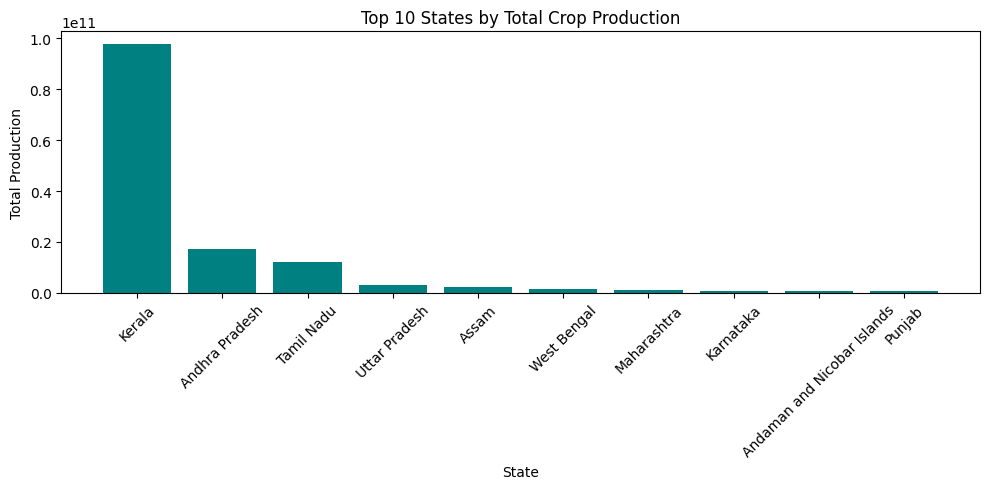

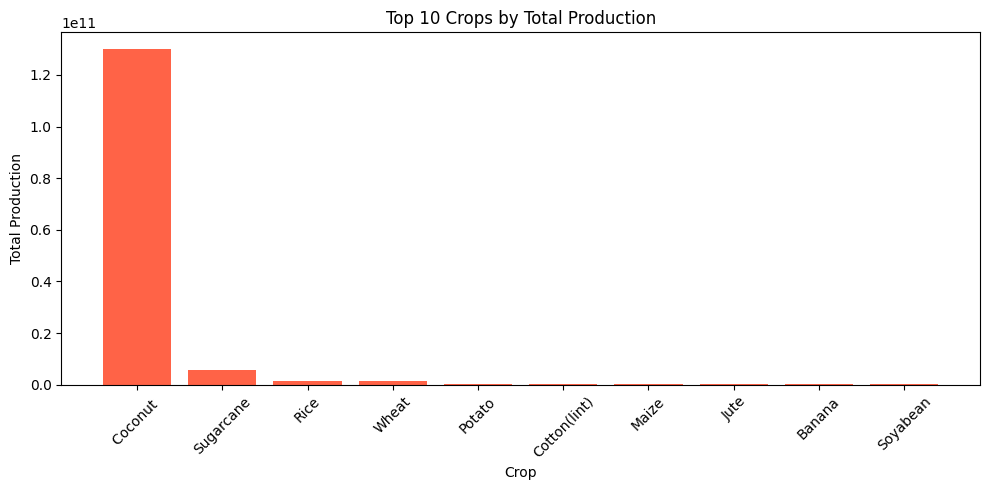

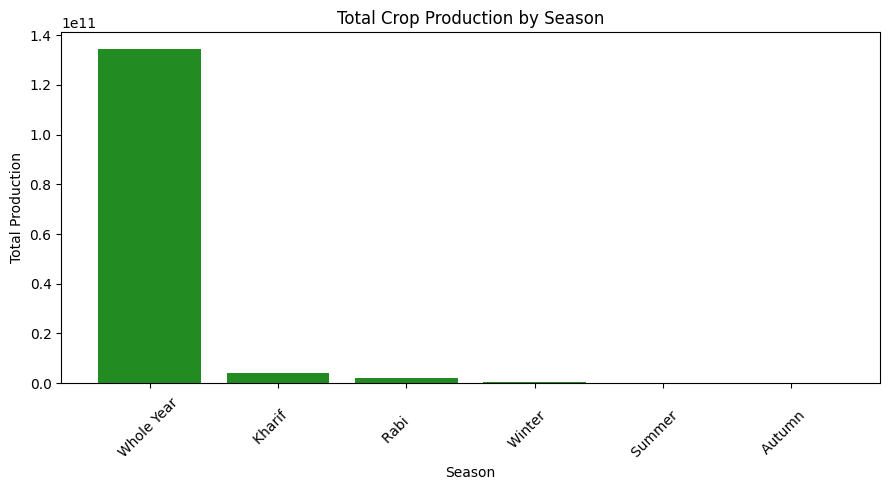

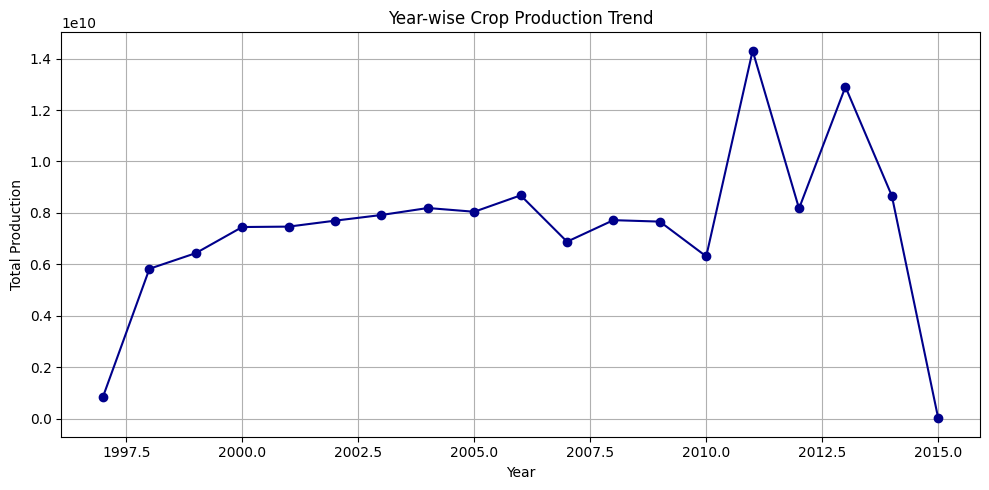

+---------+-----+
|Crop_Year|count|
+---------+-----+
|     1997| 8899|
|     1998|11262|
|     1999|12441|
|     2000|13553|
|     2001|13293|
|     2002|16536|
|     2003|17139|
|     2004|13858|
|     2005|13519|
|     2006|13976|
|     2007|14269|
|     2008|14230|
|     2009|13767|
|     2010|13793|
|     2011|13791|
|     2012|13184|
|     2013|13475|
|     2014|10815|
|     2015|  561|
+---------+-----+



In [6]:
# Fetching aggregated pandas dataframes for plotting
state_pd = state_production.limit(10).toPandas()
crop_pd = crop_production.limit(10).toPandas()
season_pd = season_production.toPandas()

year_pd = cleaned_df.groupBy("Crop_Year") \
    .sum("Production") \
    .withColumnRenamed("sum(Production)", "Total_Production") \
    .orderBy("Crop_Year") \
    .toPandas()

# Top 10 States
plt.figure(figsize=(10, 5))
plt.bar(state_pd["State_Name"], state_pd["Total_Production"], color="teal")
plt.title("Top 10 States by Total Crop Production")
plt.xlabel("State")
plt.ylabel("Total Production")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Top 10 Crops
plt.figure(figsize=(10, 5))
plt.bar(crop_pd["Crop"], crop_pd["Total_Production"], color="tomato")
plt.title("Top 10 Crops by Total Production")
plt.xlabel("Crop")
plt.ylabel("Total Production")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Production by Season
plt.figure(figsize=(9, 5))
plt.bar(season_pd["Season"], season_pd["Total_Production"], color="forestgreen")
plt.title("Total Crop Production by Season")
plt.xlabel("Season")
plt.ylabel("Total Production")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Year-wise Trend
plt.figure(figsize=(10, 5))
plt.plot(year_pd["Crop_Year"], year_pd["Total_Production"], marker="o", linestyle="-", color="darkblue")
plt.title("Year-wise Crop Production Trend")
plt.xlabel("Year")
plt.ylabel("Total Production")
plt.grid(True)
plt.tight_layout()
plt.show()

# Distribution profile by year to support trend interpretation
year_count = cleaned_df.groupBy("Crop_Year").count().orderBy("Crop_Year")
year_count.show(25)

### 8. ML Preprocessing Pipeline (String Indexing, One-Hot Encoding, & Vector Assembler)

In [7]:
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml import Pipeline

# Subset data for modeling
ml_df = cleaned_df.select(
    "State_Name", "District_Name", "Crop_Year", "Season", "Crop", "Area", "Production"
)

# Transform categorical values to indices
state_indexer = StringIndexer(inputCol="State_Name", outputCol="State_Index", handleInvalid="keep")
district_indexer = StringIndexer(inputCol="District_Name", outputCol="District_Index", handleInvalid="keep")
season_indexer = StringIndexer(inputCol="Season", outputCol="Season_Index", handleInvalid="keep")
crop_indexer = StringIndexer(inputCol="Crop", outputCol="Crop_Index", handleInvalid="keep")

# Encode categorical indicators using OneHotEncoder
encoder = OneHotEncoder(
    inputCols=["State_Index", "District_Index", "Season_Index", "Crop_Index"],
    outputCols=["State_Vector", "District_Vector", "Season_Vector", "Crop_Vector"]
)

# Assemble all vector attributes and continuous elements into "features"
assembler = VectorAssembler(
    inputCols=["State_Vector", "District_Vector", "Season_Vector", "Crop_Vector", "Crop_Year", "Area"],
    outputCol="features"
)

# Chain stages inside the ML Pipeline
preprocessing_pipeline = Pipeline(stages=[
    state_indexer, district_indexer, season_indexer, crop_indexer,
    encoder, assembler
])

# Splitting Dataset based on historical Threshold Year (2012)
train_df = ml_df.filter(col("Crop_Year") <= 2012)
test_df = ml_df.filter(col("Crop_Year") > 2012)

print("Training records count:", train_df.count())
print("Testing records count:", test_df.count())

# Fit & Transform to acquire model matrices
preprocessing_model = preprocessing_pipeline.fit(train_df)
train_processed = preprocessing_model.transform(train_df)
test_processed = preprocessing_model.transform(test_df)

train_processed.select("features", "Production").show(5, truncate=False)

Training records count: 217510
Testing records count: 24851
+--------------------------------------------------------------+----------+
|features                                                      |Production|
+--------------------------------------------------------------+----------+
|(797,[30,603,674,692,795,796],[1.0,1.0,1.0,1.0,2002.0,413.0]) |28.8      |
|(797,[30,606,673,693,795,796],[1.0,1.0,1.0,1.0,2010.0,1.0])   |0.5       |
|(797,[12,58,673,689,795,796],[1.0,1.0,1.0,1.0,2001.0,15170.0])|17446.0   |
|(797,[12,58,672,679,795,796],[1.0,1.0,1.0,1.0,2003.0,6246.0]) |10718.0   |
|(797,[12,56,672,702,795,796],[1.0,1.0,1.0,1.0,1999.0,5096.0]) |637.0     |
+--------------------------------------------------------------+----------+
only showing top 5 rows


### 9. Machine Learning Model: Linear Regression

In [8]:
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator

# Define the Evaluator object
evaluator = RegressionEvaluator(labelCol="Production", predictionCol="Prediction")

# Model Training & Inference
lr = LinearRegression(featuresCol="features", labelCol="Production", predictionCol="Prediction")
lr_model = lr.fit(train_processed)
lr_predictions = lr_model.transform(test_processed)

# Evaluation Metrics calculation
rmse = evaluator.evaluate(lr_predictions, {evaluator.metricName: "rmse"})
mae = evaluator.evaluate(lr_predictions, {evaluator.metricName: "mae"})
r2 = evaluator.evaluate(lr_predictions, {evaluator.metricName: "r2"})

print("Linear Regression Results:")
print("RMSE:", rmse)
print("MAE:", mae)
print("R2 Score:", r2)

lr_predictions.select("Production", "Prediction").show(10, truncate=False)

Linear Regression Results:
RMSE: 19690160.99118886
MAE: 2058879.5463892212
R2 Score: 0.18818488036687653
+----------+--------------------+
|Production|Prediction          |
+----------+--------------------+
|916.0     |1.0321655943528399E7|
|17131.0   |-597855.6820138469  |
|3699.0    |-116059.51176405698 |
|1.0       |-349942.3531001955  |
|768771.0  |5138568.804220423   |
|10589.0   |1059320.9893305302  |
|1372.0    |-1143504.5463657305 |
|1245.0    |-1549252.6045753285 |
|246.0     |896756.9981131628   |
|1549.0    |1106101.0492282137  |
+----------+--------------------+
only showing top 10 rows


### 10. Machine Learning Model: Decision Tree Regressor

In [9]:
from pyspark.ml.regression import DecisionTreeRegressor

# Model training & Inference
dt = DecisionTreeRegressor(featuresCol="features", labelCol="Production", predictionCol="Prediction", maxDepth=5)
dt_model = dt.fit(train_processed)
dt_predictions = dt_model.transform(test_processed)

# Evaluation Metrics calculation
dt_rmse = evaluator.evaluate(dt_predictions, {evaluator.metricName: "rmse"})
dt_mae = evaluator.evaluate(dt_predictions, {evaluator.metricName: "mae"})
dt_r2 = evaluator.evaluate(dt_predictions, {evaluator.metricName: "r2"})

print("Decision Tree Results:")
print("RMSE:", dt_rmse)
print("MAE:", dt_mae)
print("R2 Score:", dt_r2)

dt_predictions.select("Production", "Prediction").show(10)

Decision Tree Results:
RMSE: 10847101.176898254
MAE: 381631.81227104354
R2 Score: 0.7536310437334184
+----------+------------------+
|Production|        Prediction|
+----------+------------------+
|     916.0| 2074.552334335058|
|   17131.0|29040.248886751473|
|    3699.0| 2074.552334335058|
|       1.0| 2074.552334335058|
|  768771.0|109974.40794446193|
|   10589.0|29040.248886751473|
|    1372.0| 2074.552334335058|
|    1245.0| 2074.552334335058|
|     246.0| 2074.552334335058|
|    1549.0| 75951.59544128647|
+----------+------------------+
only showing top 10 rows


### 11. Machine Learning Model: Random Forest Regressor

In [10]:
from pyspark.ml.regression import RandomForestRegressor

# Model training & Inference
rf = RandomForestRegressor(featuresCol="features", labelCol="Production", predictionCol="Prediction", numTrees=20, maxDepth=5)
rf_model = rf.fit(train_processed)
rf_predictions = rf_model.transform(test_processed)

# Evaluation Metrics calculation
rf_rmse = evaluator.evaluate(rf_predictions, {evaluator.metricName: "rmse"})
rf_mae = evaluator.evaluate(rf_predictions, {evaluator.metricName: "mae"})
rf_r2 = evaluator.evaluate(rf_predictions, {evaluator.metricName: "r2"})

print("Random Forest Results:")
print("RMSE:", rf_rmse)
print("MAE:", rf_mae)
print("R2 Score:", rf_r2)

rf_predictions.select("Production", "Prediction").show(10)

Random Forest Results:
RMSE: 11527234.619868053
MAE: 531438.2519284462
R2 Score: 0.7217668537082336
+----------+------------------+
|Production|        Prediction|
+----------+------------------+
|     916.0| 600832.6190630203|
|   17131.0| 41185.96584624569|
|    3699.0| 35512.28371326099|
|       1.0| 287370.9601980257|
|  768771.0|141885.25329412002|
|   10589.0| 43381.23323216198|
|    1372.0| 44134.40989889409|
|    1245.0| 44134.40989889409|
|     246.0| 44134.40989889409|
|    1549.0| 275620.3107792374|
+----------+------------------+
only showing top 10 rows


### 12. Regressor Comparisons & Predictions Visualization

+-----------------+--------------------+------------------+-------------------+
|Model            |RMSE                |MAE               |R2                 |
+-----------------+--------------------+------------------+-------------------+
|Decision Tree    |1.0847101176898254E7|381631.81227104354|0.7536310437334184 |
|Random Forest    |1.1527234619868053E7|531438.2519284462 |0.7217668537082336 |
|Linear Regression|1.969016099118886E7 |2058879.5463892212|0.18818488036687653|
+-----------------+--------------------+------------------+-------------------+



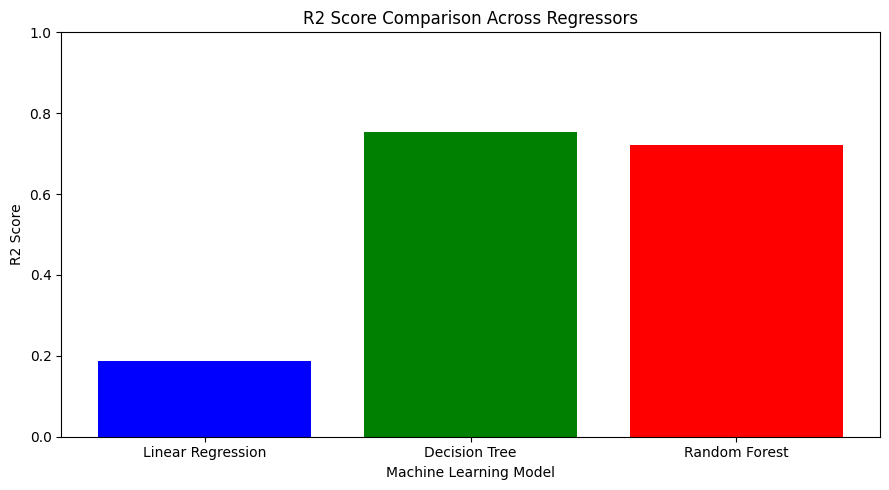

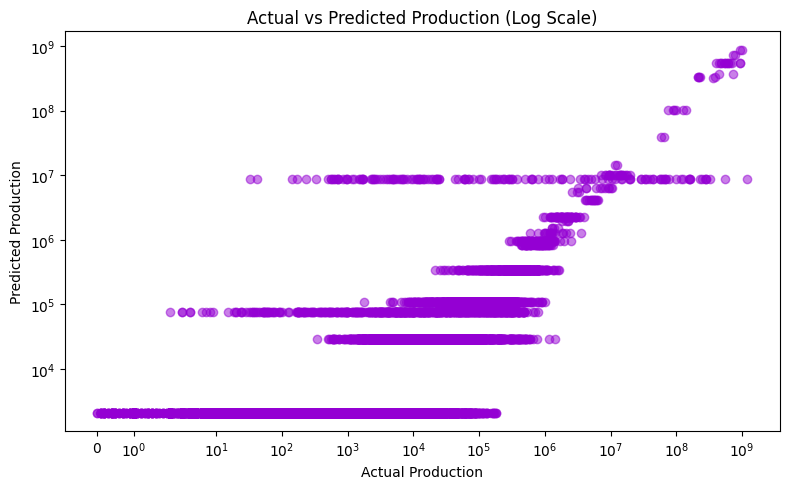

In [11]:
# Put results into a single Spark DataFrame for comparison
results = [
    ("Linear Regression", rmse, mae, r2),
    ("Decision Tree", dt_rmse, dt_mae, dt_r2),
    ("Random Forest", rf_rmse, rf_mae, rf_r2)
]
comparison_df = spark.createDataFrame(results, ["Model", "RMSE", "MAE", "R2"])
comparison_df.orderBy("RMSE").show(truncate=False)

# Convert to pandas for plotting
results_pd = comparison_df.toPandas()
plt.figure(figsize=(9, 5))
plt.bar(results_pd["Model"], results_pd["R2"], color=["blue", "green", "red"])
plt.title("R2 Score Comparison Across Regressors")
plt.xlabel("Machine Learning Model")
plt.ylabel("R2 Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

# Actual vs Predicted Plots
prediction_pd = dt_predictions.select("Production", "Prediction").toPandas()
plt.figure(figsize=(8, 5))
plt.scatter(prediction_pd["Production"], prediction_pd["Prediction"], alpha=0.5, color="darkviolet")
plt.xscale("symlog")
plt.yscale("symlog")
plt.xlabel("Actual Production")
plt.ylabel("Predicted Production")
plt.title("Actual vs Predicted Production (Log Scale)")
plt.tight_layout()
plt.show()

### 13. Decision Tree Feature Importance Mapping

Feature
State_Vector       0.509011
Area               0.201662
Crop_Vector        0.129031
District_Vector    0.098574
Crop_Year          0.061721
Season_Vector      0.000000
Name: Importance, dtype: float64


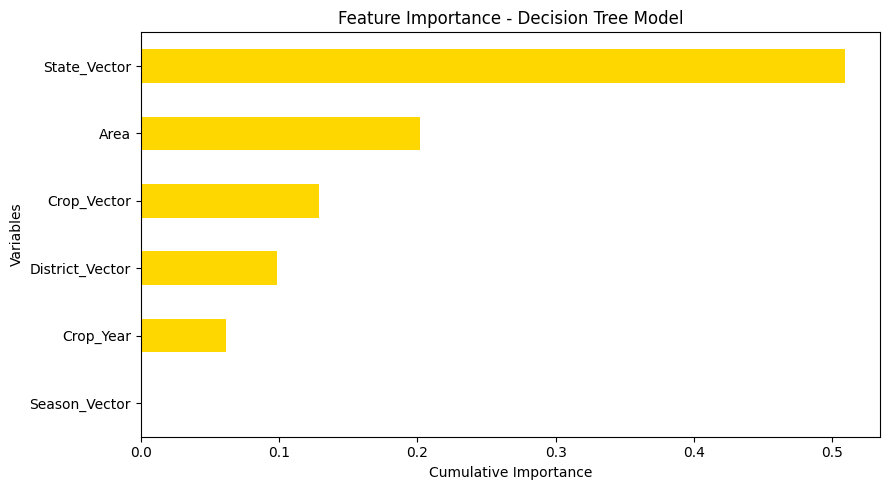

In [12]:
# Recover and map categorical dimensions
encoder_model = preprocessing_model.stages[4]
category_sizes = encoder_model.categorySizes

# Compile structural flat list of transformed names
feature_names = (
    ["State_Vector"] * (category_sizes[0] - 1)
    + ["District_Vector"] * (category_sizes[1] - 1)
    + ["Season_Vector"] * (category_sizes[2] - 1)
    + ["Crop_Vector"] * (category_sizes[3] - 1)
    + ["Crop_Year", "Area"]
)

importance_values = dt_model.featureImportances.toArray()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Group and sum importances by variable group
importance_summary = importance_df.groupby("Feature")["Importance"].sum().sort_values(ascending=True)
print(importance_summary.sort_values(ascending=False))

# Horizontal bar plot
plt.figure(figsize=(9, 5))
importance_summary.plot(kind="barh", color="gold")
plt.title("Feature Importance - Decision Tree Model")
plt.xlabel("Cumulative Importance")
plt.ylabel("Variables")
plt.tight_layout()
plt.show()